# HU-5: agrupar medicamentos con K-Means


## 1. Cargar los datos

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

# dtype indica que nregistro y cn son texto, porque son códigos y no cantidades
df = pd.read_csv("../data/HU4_medicamentos_diabetes_limpio.csv", dtype={"nregistro": str, "cn": str})

# Al leer un CSV las fechas llegan como texto, así que volvemos a pasar estado_aut a fecha
df["estado_aut"] = pd.to_datetime(df["estado_aut"])

print(df.shape)
print("Nulos:", df.isna().sum().sum())

(827, 28)
Nulos: 0


## 2. Preparar las columnas numéricas

K-Means calcula distancias, así que todo tiene que estar en números. Antes de elegir las columnas creamos dos nuevas a partir de datos que no son numéricos:

`antiguedad_anios`: los años que han pasado desde la autorización.

`es_inyectable`: 1 si la forma farmacéutica es inyectable y 0 si no.

In [2]:
# .dt.year saca el año de una fecha
df["antiguedad_anios"] = 2026 - df["estado_aut"].dt.year

# Creamos la columna con 0 en todas las filas y ponemos 1 solo en los inyectables
df["es_inyectable"] = 0
df.loc[df["forma_farmaceutica_simplificada"] == "INYECTABLE", "es_inyectable"] = 1

df[["nombre", "antiguedad_anios", "es_inyectable"]].head()

,nombre,antiguedad_anios,es_inyectable
0,ACARBOSA TECNIGEN 100 mg COMPRIMIDOS,17,0
1,ACARBOSA TECNIGEN 50 mg COMPRIMIDOS,17,0
2,ACTRAPID INNOLET 100 UI/ML SOLUCION INYECTABLE...,26,1
3,BIGETRA 150 MG CAPSULAS DURAS,2,0
4,BYDUREON 2 MG POLVO Y DISOLVENTE PARA SUSPENSI...,12,1


Estas son las columnas que usa el modelo y las que dejamos fuera:

| Columnas | ¿Las usamos? | Motivo |
|---|---|---|
| `precio_pvp_iva`, `palabras_seccion_4_4`, `numero_tablas`, `indicador_riesgo_severo`, `num_excipientes`, `dosis_numero`, `num_principios_activos`, `antiguedad_anios` | Sí | Son cantidades que describen el medicamento |
| `generico`, `comercializado`, `afecta_conduccion`, `tratamiento_larga_duracion`, `es_inyectable` | Sí | Son características 0/1 |
| `nregistro`, `cn`, `nombre`, `pactivos`, `labtitular`, `labcomercializador`, `dosis`, `estado_aut` | No | Son códigos o texto. Los usamos después para interpretar los grupos |
| `estado` | No | Casi siempre dice lo mismo que `comercializado` |
| `tiene_revision` | No | Está muy relacionada con `comercializado` |
| `forma_farmaceutica_simplificada`, `vias_administracion`, `dosis_por_ml` | No | Lo más importante que aportan ya está en `es_inyectable` |
| `num_registros_atc`, `biosimilar` | No | Casi no cambian: valen lo mismo en 825 de las 827 filas |
| `dosis_numero_2` | No | Ya sabemos si hay combinación con `num_principios_activos` |
| `tiene_foto_materiales` | No | Dice si hay una foto en CIMA, no cómo es el medicamento |

In [3]:
columnas_modelo = [
    "precio_pvp_iva",
    "palabras_seccion_4_4",
    "numero_tablas",
    "indicador_riesgo_severo",
    "num_excipientes",
    "dosis_numero",
    "num_principios_activos",
    "antiguedad_anios",
    "generico",
    "comercializado",
    "afecta_conduccion",
    "tratamiento_larga_duracion",
    "es_inyectable",
]

# X es la tabla que recibe el modelo
X = df[columnas_modelo]

print(X.shape)
print("Nulos en X:", X.isna().sum().sum())
X.describe().T[["min", "mean", "max"]].round(2)

(827, 13)
Nulos en X: 0


,min,mean,max
precio_pvp_iva,0.95,20.30,133.47
palabras_seccion_4_4,0.00,1236.47,3692.00
numero_tablas,0.00,3.53,32.00
indicador_riesgo_severo,2.00,10.94,36.00
num_excipientes,0.00,1.96,9.00
dosis_numero,0.00,78.99,1000.00
num_principios_activos,1.00,1.12,2.00
antiguedad_anios,0.00,13.78,67.00
generico,0.00,0.74,1.00
comercializado,0.00,0.81,1.00


## 3. Escalamos los datos

Las columnas tienen rangos muy distintos: `palabras_seccion_4_4` llega a 3692 y `generico` solo vale 0 o 1. Como K-Means usa distancias, sin escalar las columnas con números más grandes sería las mas importantes.

`StandardScaler` cambia cada columna para que tenga **media 0 y desviación típica 1**

In [4]:
escalador = StandardScaler()

# fit_transform calcula la media y la desviación de cada columna
X_escalado = escalador.fit_transform(X)

## 4. Elegimos el número de grupos k

K lo tenemos que decidir nosotros. Entrenamos el modelo con K de 2 a 10 y miramos dos medidas:

- **Inercia:** es la suma de las distancias al cuadrado de cada medicamento a su centroide. Cuanto más bja, más compactos son los grupos, pero siempre baja al añadir mas grupos. Por eso buscamos el **codo**, el punto donde empieza a bajar más despacio.
- **Silhouette:** va de -1 a 1 e indica si cada medicamento está más cerca de su grupo que del grupo vecino. Cuanto más alto, mejor separados están.

En `KMeans` usamos dos parámetros más:

- `random_state=42` fija el azar para obtener siempre el mismo resultado.
- `n_init=50` prueba 50 puntos de partida distintos y se queda con el mejor.

In [5]:
valores_k = [2, 3, 4, 5, 6, 7, 8, 9, 10]
inercias = []
silhouettes = []

for k in valores_k:
    modelo_prueba = KMeans(n_clusters=k, random_state=42, n_init=50)
    # entrena y devuelve el grupo de cada medicamento
    grupos = modelo_prueba.fit_predict(X_escalado)     

    inercia = modelo_prueba.inertia_
    silhouette = silhouette_score(X_escalado, grupos)

    inercias.append(inercia)
    silhouettes.append(silhouette)
    print("K =", k, "| inercia:", round(inercia), "| silhouette:", round(silhouette, 3))

K = 2 | inercia: 8775 | silhouette: 0.211


K = 3 | inercia: 7603 | silhouette: 0.235


K = 4 | inercia: 6693 | silhouette: 0.255


K = 5 | inercia: 5829 | silhouette: 0.286


K = 6 | inercia: 5005 | silhouette: 0.292


K = 7 | inercia: 4492 | silhouette: 0.276


K = 8 | inercia: 4108 | silhouette: 0.292


K = 9 | inercia: 3822 | silhouette: 0.298


K = 10 | inercia: 3587 | silhouette: 0.306


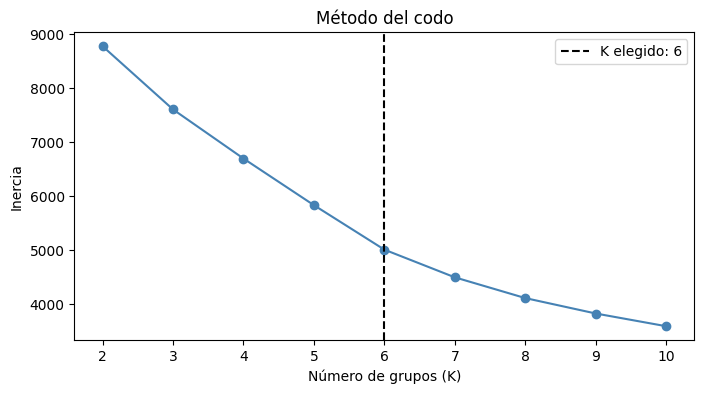

In [6]:
# Gráfica del codo
plt.figure(figsize=(8, 4))
plt.plot(valores_k, inercias, marker="o", color="steelblue")
plt.axvline(6, color="black", linestyle="--", label="K elegido: 6")
plt.title("Método del codo")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Inercia")
plt.legend()
plt.savefig("../reportes/figuras/h5_codo.png", dpi=150, bbox_inches="tight")
plt.show()

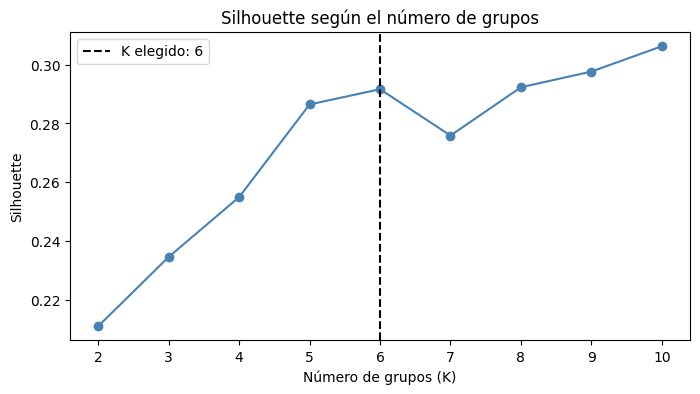

In [7]:
# Gráfica de silhouette
plt.figure(figsize=(8, 4))
plt.plot(valores_k, silhouettes, marker="o", color="steelblue")
plt.axvline(6, color="black", linestyle="--", label="K elegido: 6")
plt.title("Silhouette según el número de grupos")
plt.xlabel("Número de grupos (K)")
plt.ylabel("Silhouette")
plt.legend()
plt.savefig("../reportes/figuras/h5_silhouette.png", dpi=150, bbox_inches="tight")
plt.show()

**Elección: K = 6.** Lo elegimos por tres motivos:

- **Silhouette:** con K = 6 sale 0,292. Es mejor que con 5 (0,286) y con 7 (0,276). Con K = 8 slo iguala ese valor y con 9 y 10 sube muy poco (hasta 0,306).
2. **Codo:** la inercia baja, así que no hay un codo muy claro. Por eso nos le damos mas importancia a silhouette.
3. **Interpretación:** 6 grupos somos capaces de poder explicar y nombrar los grupos y sus patrones comunes.

## 5. Entrenar el modelo final

In [8]:
modelo = KMeans(n_clusters=6, random_state=42, n_init=50)

# Guardamos en una columna nueva el grupo (de 0 a 5) de cada medicamento
df["cluster"] = modelo.fit_predict(X_escalado)

print("Silhouette final:", round(silhouette_score(X_escalado, df["cluster"]), 3))
df["cluster"].value_counts().sort_index()

Silhouette final: 0.292


cluster
0     29
1    335
2    108
3    227
4     77
5     51
Name: count, dtype: int64

## 6. Analizamos los grupos

Analizamos los grupos obtenidos para poder sacar patrones comunes entre sus intregrantes

In [9]:
# Media de cada columna en cada grupo
# groupby separa las filas por grupo y mean calcula la media de cada columna
medias = df.groupby("cluster")[columnas_modelo].mean().round(2)
medias.T

cluster,0,1,2,3,4,5
precio_pvp_iva,1.58,14.44,44.43,4.25,38.10,62.87
palabras_seccion_4_4,853.55,743.67,1308.28,1868.65,1854.00,793.00
numero_tablas,1.10,1.42,4.52,1.24,18.74,3.84
indicador_riesgo_severo,3.07,10.88,12.62,8.97,18.39,9.82
num_excipientes,0.21,1.98,1.44,2.02,2.61,2.80
dosis_numero,901.72,66.86,40.80,35.43,53.67,3.84
num_principios_activos,1.00,1.00,1.90,1.00,1.00,1.12
antiguedad_anios,11.62,13.07,7.94,20.23,6.04,14.98
generico,1.00,0.84,0.47,0.85,0.75,0.00
comercializado,0.59,0.82,0.94,0.73,0.95,0.75


In [10]:
# Principios activos más frecuentes de cada grupo
for numero in range(6):
    filas_grupo = df[df["cluster"] == numero]
    print("Grupo", numero, "- medicamentos:", len(filas_grupo), "- mediana del precio:", filas_grupo["precio_pvp_iva"].median())
    print(filas_grupo["pactivos"].value_counts().head(5))
    print()

Grupo 0 - medicamentos: 29 - mediana del precio: 1.86
pactivos
METFORMINA HIDROCLORURO    28
METFORMINA                  1
Name: count, dtype: int64

Grupo 1 - medicamentos: 335 - mediana del precio: 13.27
pactivos
IRBESARTAN                               60
TELMISARTAN                              56
REPAGLINIDA                              35
SITAGLIPTINA HIDROCLORURO MONOHIDRATO    30
GLIMEPIRIDA                              26
Name: count, dtype: int64

Grupo 2 - medicamentos: 108 - mediana del precio: 36.19
pactivos
VILDAGLIPTINA, METFORMINA HIDROCLORURO                            32
SITAGLIPTINA HIDROCLORURO MONOHIDRATO, METFORMINA HIDROCLORURO    11
SITAGLIPTINA HIDROCLORURO, METFORMINA HIDROCLORURO                 8
RAMIPRIL, BISOPROLOL FUMARATO                                      6
SEMAGLUTIDA                                                        6
Name: count, dtype: int64

Grupo 3 - medicamentos: 227 - mediana del precio: 2.5
pactivos
SIMVASTATINA         82
LOSARTAN POTAS

## 7. Poner nombre a los grupos

Con las tablas anteriores y con ayuda de la IA para poder interpretar los tipos de medicamentos y patrones, damos un nombre a cada grupo:

| Grupo | Nombre | Por qué |
|---|---|---|
| 0 | Metformina barata de dosis alta | Todo es metformina, con una dosis media de 902 mg y un precio medio de 1,58 € |
| 1 | Comprimidos genéricos de uso general | Es el grupo más grande, conteine comprimidos, 84 % genéricos y con valores cerca de la media. Mezcla irbesartán, telmisartán, repaglinida y sitagliptina |
| 2 | Combinaciones de dos principios activos | Tienen 1,9 principios activos de media y son más caros (mediana de 36,19 €). Sobre todo vildagliptina o sitagliptina con metformina |
| 3 | Baratos de larga duración | Todos son de larga duración y una mediana de 2,50 €. Sobre todo simvastatina, losartán y ramipril |
| 4 | Anticoagulantes con ficha compleja | Rivaroxabán, dabigatrán, apixabán y edoxabán. Tienen 18,7 tablas y 18,4 menciones de "grave" de media |
| 5 | Inyectables no genéricos | Todos son inyectables y ninguno es genérico. Son los más caros (mediana de 48,80 €). Sobre todo insulinas |

In [11]:
# Diccionario con número de grupo y nombre
nombres_grupos = {
    0: "Metformina barata de dosis alta",
    1: "Comprimidos genéricos de uso general",
    2: "Combinaciones de dos principios activos",
    3: "Baratos de larga duración",
    4: "Anticoagulantes con ficha compleja",
    5: "Inyectables no genéricos",
}

# .map traduce cada número usando el diccionario
df["perfil"] = df["cluster"].map(nombres_grupos)

df["perfil"].value_counts()

perfil
Comprimidos genéricos de uso general       335
Baratos de larga duración                  227
Combinaciones de dos principios activos    108
Anticoagulantes con ficha compleja          77
Inyectables no genéricos                    51
Metformina barata de dosis alta             29
Name: count, dtype: int64

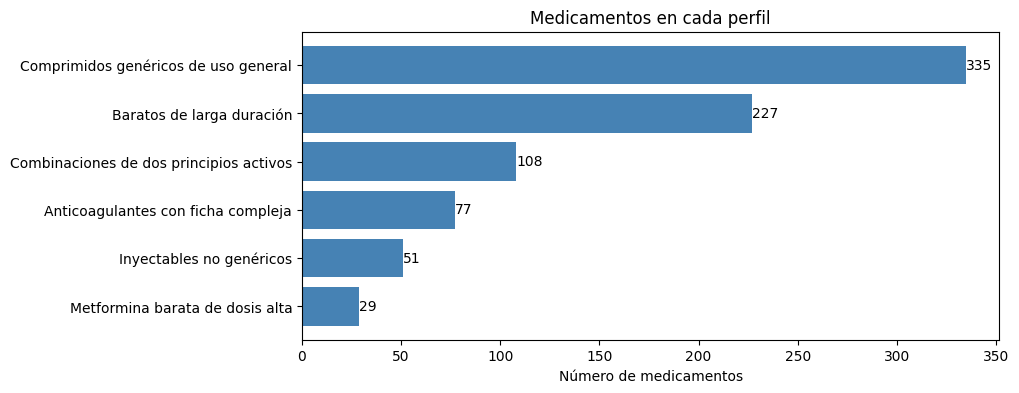

In [12]:
# Número de medicamentos de cada grupo
conteo_perfiles = df["perfil"].value_counts().sort_values()

plt.figure(figsize=(9, 4))
barras = plt.barh(conteo_perfiles.index, conteo_perfiles.values, color="steelblue")
plt.bar_label(barras)     
# escribe el número al final de cada barra
plt.title("Medicamentos en cada perfil")
plt.xlabel("Número de medicamentos")
plt.savefig("../reportes/figuras/h5_tamano_perfiles.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Grupos en un dibujo

El modelo usa 13 columnas, pero una gráfica solo tiene 2 ejes. Tenemmops que utilizar **PCA** para resumir las 13 columnas en 2 nuevas (`pca_1` y `pca_2`) intentando perder la menor información posible.


In [13]:
pca = PCA(n_components=2)
puntos = pca.fit_transform(X_escalado)

# primera columna de puntos
df["pca_1"] = puntos[:, 0]     
 # segunda columna de puntos
df["pca_2"] = puntos[:, 1]    

# explained_variance_ratio_ dice cuánta información conserva cada eje
informacion = pca.explained_variance_ratio_.sum() * 100
print("Información que conserva el dibujo:", round(informacion, 1), "%")

Información que conserva el dibujo: 38.5 %


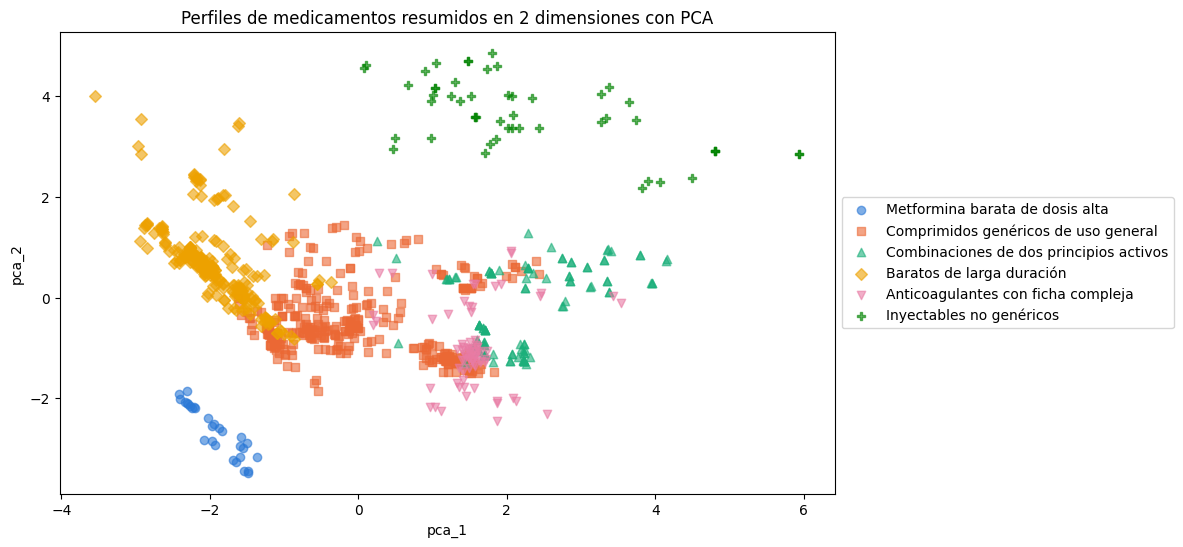

In [14]:
colores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
marcadores = ["o", "s", "^", "D", "v", "P"]

plt.figure(figsize=(10, 6))

# Dibujamos cada grupo por separado para darle su color, su forma y su nombre en la leyenda
for numero in range(6):
    filas_grupo = df[df["cluster"] == numero]
    plt.scatter(
        filas_grupo["pca_1"],
        filas_grupo["pca_2"],
        color=colores[numero],
        marker=marcadores[numero],
        alpha=0.6,
        label=nombres_grupos[numero],
    )

plt.title("Perfiles de medicamentos resumidos en 2 dimensiones con PCA")
plt.xlabel("pca_1")
plt.ylabel("pca_2")
# bbox_to_anchor coloca la leyenda fuera de la gráfica para que no tape los puntos
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.savefig("../reportes/figuras/h5_pca.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Guardamos el CSV

In [15]:
# Borramos las columnas que solo necestimos dentro del cuaderno
df_salida = df.drop(columns=["antiguedad_anios", "es_inyectable", "pca_1", "pca_2"])

df_salida.to_csv("../data/HU5_medicamentos_diabetes_clusters.csv", index=False, encoding="utf-8-sig")